In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_ddm_posterior,
    load_behavioral_data,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
MODEL = "HDDM_Base_Lag1-stpdrift"

## Figure S6
Per-subject correlation between posterior draws of `v_choice_prev1` (fixed drift bias) and `z_choice_prev1` (starting-point bias) for the SP-Drift-CH model (`HDDM_Base_Lag1-stpdrift`), one histogram per dataset. For each subject, the correlation is computed within each MCMC chain and averaged across chains.

In [2]:
behavioral_data = load_behavioral_data()

Per-subject v_choice_prev1 vs. z_choice_prev1 posterior correlation:
  equalIndifference: mean = -0.331, sd = 0.055, n = 216
  equalIndifference: min = -0.481, max = -0.174
  equalRange: mean = -0.192, sd = 0.028, n = 216
  equalRange: min = -0.245, max = -0.090
  sheng2020: mean = -0.308, sd = 0.048, n = 328
  sheng2020: min = -0.436, max = -0.180


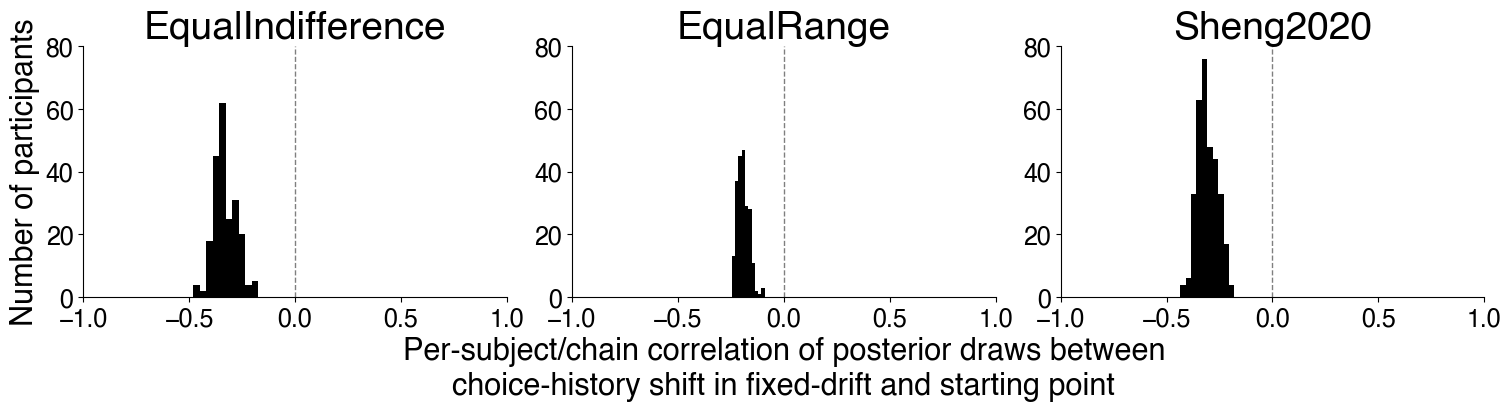

In [45]:
CORR_COLOR = "#000000"


def compute_subject_correlations(dataset):
    """Per-subject correlation between v_choice_prev1 and z_choice_prev1
    posterior draws (mean across chains), for the SP-Drift-CH model."""
    posterior = load_ddm_posterior(MODEL, dataset)
    subs = behavioral_data.query(f"dataset == '{dataset}'")["sub"].unique()

    correlations = []
    
    for sub in subs:
        v_key, z_key = f"v_choice_prev1_subj.{sub}", f"z_choice_prev1_subj.{sub}"
        if v_key not in posterior or z_key not in posterior:
            continue
        v_choice_prev1 = posterior[v_key]
        z_choice_prev1 = posterior[z_key]
        for chain in range(len(v_choice_prev1)):
            correlations.append(np.corrcoef(v_choice_prev1[chain], z_choice_prev1[chain])[0, 1])

    return np.array(correlations)



fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), layout="constrained")

print("Per-subject v_choice_prev1 vs. z_choice_prev1 posterior correlation:")
for ax, ds in zip(axes, DATASETS):
    correlations = compute_subject_correlations(ds)

    ax.hist(correlations, bins=10, color=CORR_COLOR, linewidth=0.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 80)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    print(f"  {ds}: mean = {correlations.mean():.3f}, sd = {correlations.std(ddof=1):.3f}, n = {len(correlations)}")
    print(f"  {ds}: min = {correlations.min():.3f}, max = {correlations.max():.3f}")

axes[0].set_ylabel("Number of participants")
axes[1].set_xlabel("Per-subject/chain correlation of posterior draws between\nchoice-history shift in fixed-drift and starting point")

fig.savefig("saved/figureS6.svg", dpi=300, bbox_inches="tight")
plt.show()